In [1]:
from __future__ import annotations

import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

In [2]:
from IPython.display import display, Image

DATA_DIR_NAMES = [
    'upcoding_v28_top10_ha2025_export',
]
SEARCH_ROOTS = []
for root in (
    Path.cwd(),
    Path.cwd() / 'data' / 'upcoding',
    Path.cwd().parent / 'data' / 'upcoding',
    Path('/content'),
    Path('/content/data/upcoding'),
):
    if root not in SEARCH_ROOTS and root.exists():
        SEARCH_ROOTS.append(root)


OUT = Path('outputs') / 'row_sum_distributions_outputs'
FIG = OUT / 'figures'
DATA_OUT = OUT / 'data'
for p in (OUT, FIG, DATA_OUT):
    p.mkdir(parents=True, exist_ok=True)

In [3]:
SCENARIOS = ['scenario_low', 'scenario_main', 'scenario_high']
SCENARIO_LABELS = {
    'scenario_low': 'Low',
    'scenario_main': 'Main',
    'scenario_high': 'High',
}
PALETTE = {
    'Baseline': '#4c78a8',
    'Low': '#72b7b2',
    'Main': '#f58518',
    'High': '#e45756',
}

plt.rcParams.update({
    'font.size': 8.5,
    'axes.titlesize': 9.5,
    'axes.labelsize': 8.8,
    'xtick.labelsize': 8.0,
    'ytick.labelsize': 8.0,
    'legend.fontsize': 7.5,
    'figure.titlesize': 9.5,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

In [4]:
# Helper functions
def resolve_data_dir() -> Path:
    candidate_dirs = [root / name for root in SEARCH_ROOTS for name in DATA_DIR_NAMES]
    for d in candidate_dirs:
        if (d / 'baseline_hier.csv').exists():
            return d

    candidate_zips = [root / f'{name}.zip' for root in SEARCH_ROOTS for name in DATA_DIR_NAMES]
    for zpath in candidate_zips:
        if zpath.exists():
            work = OUT / '_unzipped'
            if work.exists():
                shutil.rmtree(work)
            work.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(zpath) as z:
                z.extractall(work)

            for candidate_file in work.rglob('baseline_hier.csv'):
                return candidate_file.parent

    searched = [str(p) for p in candidate_dirs + candidate_zips]
    raise FileNotFoundError(
        'Could not find the generated export directory or zip.\n'
        'Run the data-export notebook first, or set DATA_DIR to the export folder.\n'
        f'Searched: {searched}'
    )


def hcc_cols(df: pd.DataFrame) -> list[str]:
    return [c for c in df.columns if c != 'person_id']


def row_sum_summaries(datasets: dict[str, pd.DataFrame]):
    rows, hist = [], []
    for name, df in datasets.items():
        vals = df[hcc_cols(df)].sum(axis=1)
        rows.append({
            'dataset': name,
            'mean': float(vals.mean()),
            'sd': float(vals.std(ddof=0)),
            'min': int(vals.min()),
            'p25': float(vals.quantile(0.25)),
            'median': float(vals.quantile(0.50)),
            'p75': float(vals.quantile(0.75)),
            'p90': float(vals.quantile(0.90)),
            'p95': float(vals.quantile(0.95)),
            'max': int(vals.max()),
            'zero_fraction': float((vals == 0).mean()),
        })
        vc = vals.value_counts().sort_index()
        for k, n in vc.items():
            hist.append({
                'dataset': name,
                'row_sum': int(k),
                'count': int(n),
                'fraction': float(n / len(vals)),
            })
    return pd.DataFrame(rows), pd.DataFrame(hist)


def plot_row_sums_custom(hist, version='v2'):
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    order = ['Baseline', 'Low', 'Main', 'High']
    xs = sorted(hist['row_sum'].unique())
    x = np.arange(len(xs))
    width = 0.18

    for i, name in enumerate(order):
        sub = hist[hist['dataset'].eq(name)].set_index('row_sum').reindex(xs).fillna(0)
        ax.bar(x + (i - 1.5) * width, sub['fraction'], width=width, label=name, color=PALETTE[name], alpha=0.88)

    ax.set_xticks(x)
    ax.set_xticklabels(xs, fontsize=9.5)
    ax.set_xlabel('Number of HCCs per beneficiary', fontsize=11.0)
    ax.set_ylabel('Fraction of beneficiaries', fontsize=11.0)
    ax.set_title('Distribution of HCC counts', pad=6, fontsize=11.5)
    ax.tick_params(axis='y', labelsize=9.5)

    # Styling
    ax.legend(frameon=False, ncol=4, fontsize=9.0)
    ax.grid(axis='y', alpha=0.22, linewidth=0.5)
    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.tight_layout()

    # Save and show
    fig.savefig(FIG / f'row_sum_distributions.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIG / f'row_sum_distributions.pdf', dpi=300, bbox_inches='tight')

    plt.close(fig)

In [7]:
data_dir = resolve_data_dir()
print(f"Using data directory: {data_dir}")

baseline = pd.read_csv(data_dir / 'baseline_hier.csv')
scenarios = {
    sc: pd.read_csv(data_dir / sc / 'all_hcc_upcoded_data.csv')
    for sc in SCENARIOS
    if (data_dir / sc / 'all_hcc_upcoded_data.csv').exists()
}

missing = [sc for sc in SCENARIOS if sc not in scenarios]
if missing:
    raise FileNotFoundError(
        'Missing scenario files for: ' + ', '.join(missing) + '\n'
        'Expected files like scenario_low/all_hcc_upcoded_data.csv.'
    )

datasets = {'Baseline': baseline}
for sc, df in scenarios.items():
    datasets[SCENARIO_LABELS[sc]] = df

print({name: df.shape for name, df in datasets.items()})

Using data directory: outputs/row_sum_distributions_outputs/_unzipped/content/upcoding_v28_top10_ha2025_export
{'Baseline': (5000, 116), 'Low': (5000, 116), 'Main': (5000, 116), 'High': (5000, 116)}


## Compute summaries and make the figure

Saved:
  outputs/row_sum_distributions_outputs/figures/row_sum_distributions.pdf
  outputs/row_sum_distributions_outputs/figures/row_sum_distributions.png
  outputs/row_sum_distributions_outputs/data/row_sum_summary.csv
  outputs/row_sum_distributions_outputs/data/row_sum_distribution.csv


,dataset,mean,sd,min,p25,median,p75,p90,p95,max,zero_fraction
0,Baseline,1.5172,0.660382,1,1.0,1.0,2.0,2.0,2.0,5,0.0
1,Low,1.6518,0.746563,1,1.0,2.0,2.0,2.0,3.0,6,0.0
2,Main,1.7196,0.795346,1,1.0,2.0,2.0,3.0,3.0,6,0.0
3,High,1.7886,0.821164,1,1.0,2.0,2.0,3.0,3.0,6,0.0


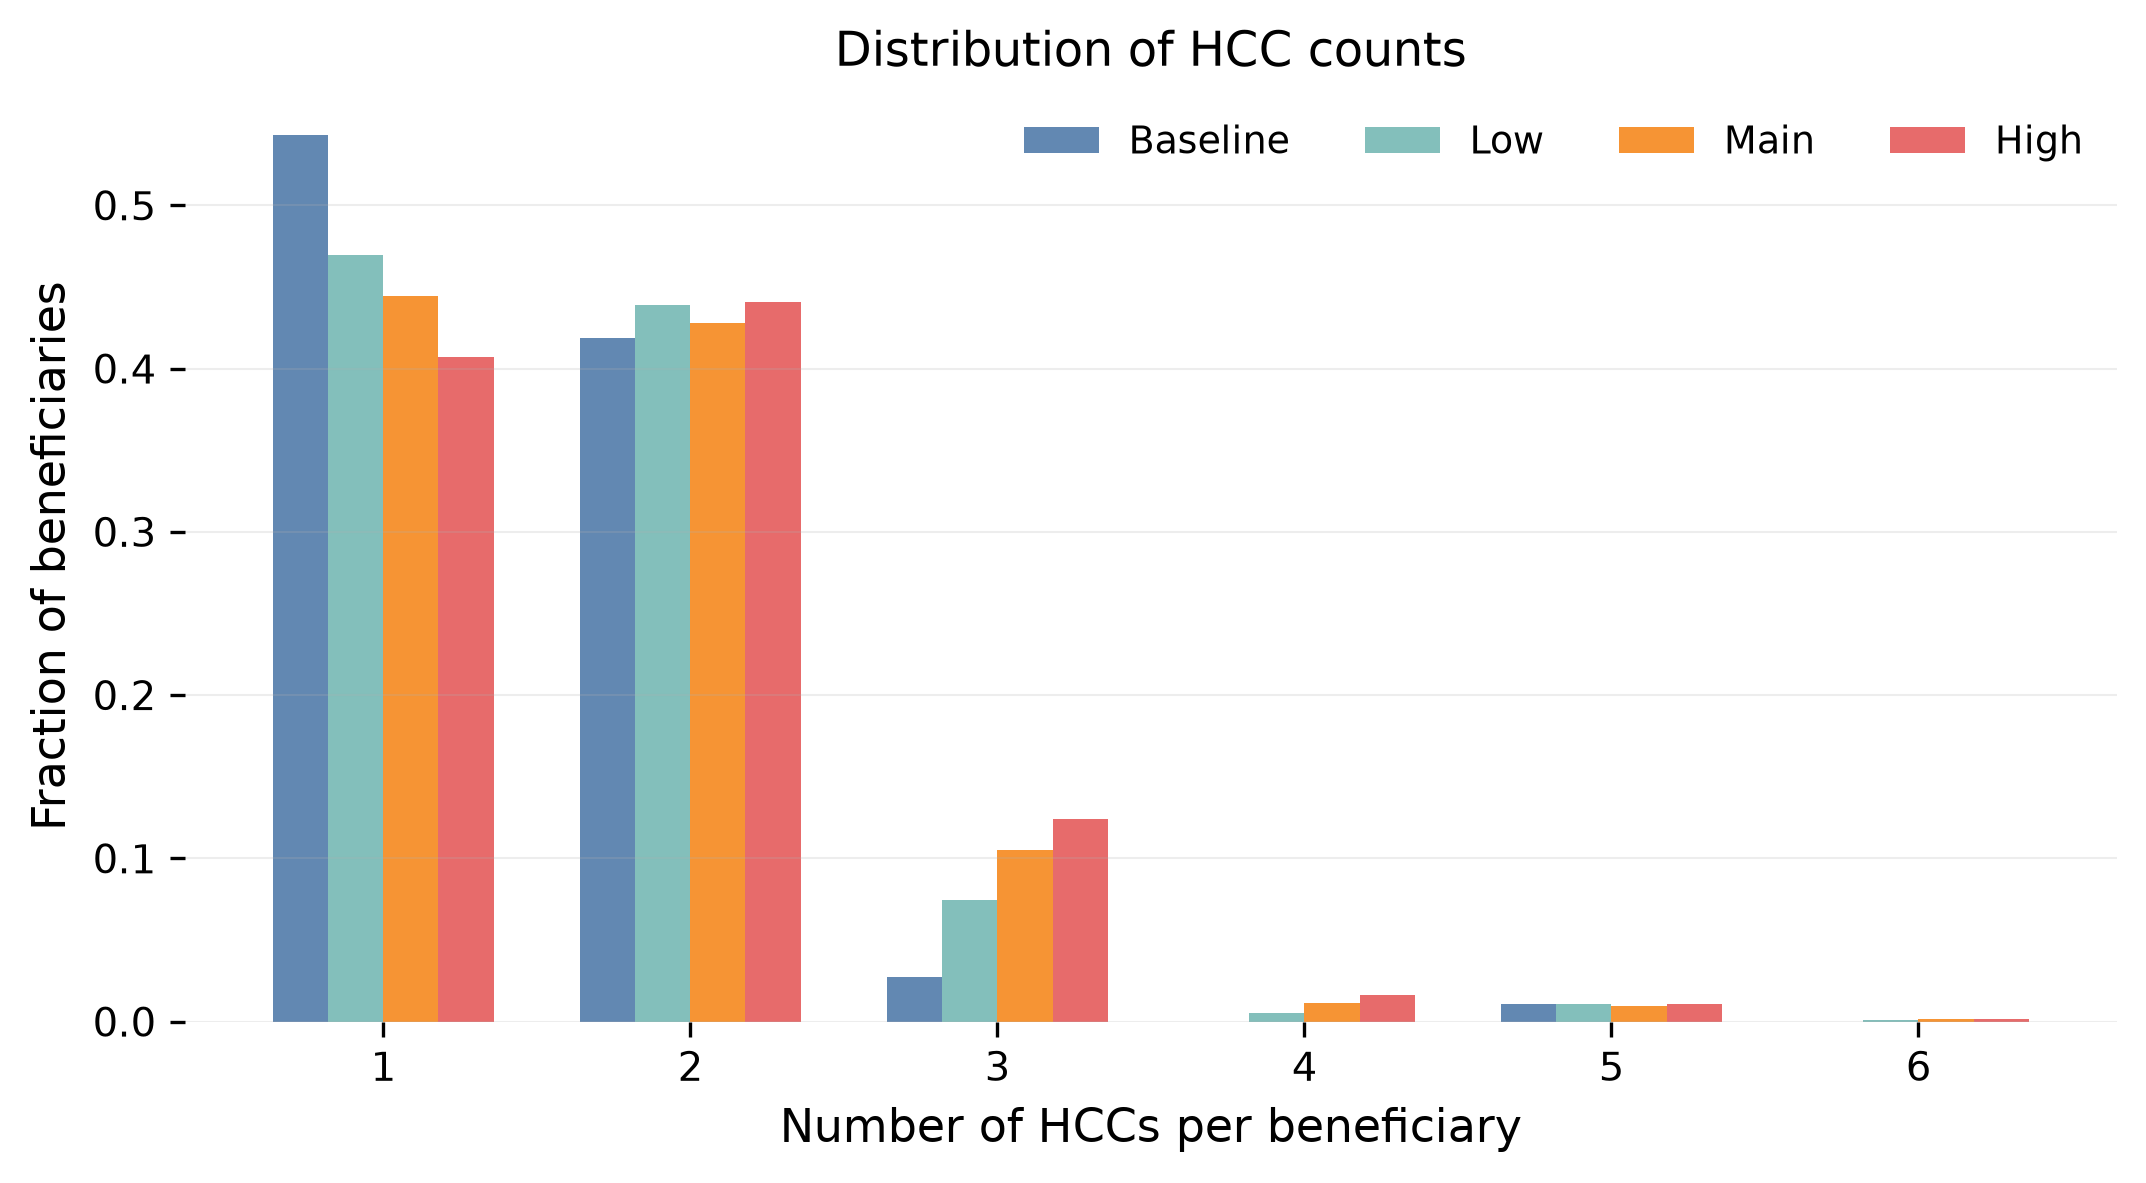

In [14]:
# Compute summaries and make the figure

version = 'v5'
row_summary, row_hist = row_sum_summaries(datasets)
row_summary.to_csv(DATA_OUT / 'row_sum_summary.csv', index=False)
row_hist.to_csv(DATA_OUT / 'row_sum_distribution.csv', index=False)

plot_row_sums_custom(row_hist, version=version)

print('Saved:')
print(' ', FIG / 'row_sum_distributions.pdf')
print(' ', FIG / 'row_sum_distributions.png')
print(' ', DATA_OUT / 'row_sum_summary.csv')
print(' ', DATA_OUT / 'row_sum_distribution.csv')

display(row_summary)
display(Image(filename=str(FIG / 'row_sum_distributions.png')))